# Machine Learning Project

CS-UY 4563 Introduction to Machine Learning, Final Project (Fall 2026) | **Thomas Motais De Narbonne, Evan Dong**

## Goal

Predict whether the Global X Artificial Intelligence & Technology ETF (**AIQ**) closes **higher (1) or lower (0) on the next trading day**, using only information available at today's close. This is a supervised binary classification task, and we compare logistic regression, an SVM and a neural network against the **54.8% "always guess up" baseline**.

## Done so far

1. **Data collection** (`yahooFinance.py`): daily OHLCV (Open, High, Low, Close, Volume) data for AIQ, QQQ, VIX and SMH from Yahoo Finance via `yfinance`.
2. **Feature creation** (`featureCreation.py`): 13 features covering AIQ's own price behavior, broad market context (QQQ, VIX) and an AI-sector signal (SMH), plus the next-day `Target`. Final dataset: 2,082 trading days (2018-07-26 to 2026-11-05), no missing values.
3. **Exploratory analysis** (`eda.py`): feature distributions, features split by target, up rate by decile and the correlation matrix. Main findings: several groups of features are strongly correlated with each other, some features are heavily skewed, and no single feature has a meaningful relationship with next-day direction.
4. **Preprocessing** (`data_preprocessing.py`): log transforms for skewed features, a chronological split (train before 2024, validation 2024, test 2025 onward), clipping at train-set 1st/99th percentiles, and standardization fit on the training set only.

## Next

Section D (supervised modeling), Section E (table of results) and Section F (conclusion).

In [1]:
%pip install -r requirements.txt

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Users\slime\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


## yahooFinance.py

In [2]:
import os
import pandas as pd

import yfinance as yf

# Pandas reads Ticker and date as data without multi_level_index=False

def download_data():
    # data for AIQ (Global X Artificial Intelligence & Technology ETF)
    aiq = yf.download('AIQ', start="2018-05-16", end="2026-11-10", interval='1d', multi_level_index=False) 
    if "AIQ.csv" not in os.listdir("Datasets/"):
        aiq.to_csv("Datasets/AIQ.csv")

    # data for QQQ (Invesco QQQ Trust)
    qqq = yf.download('QQQ', start="2018-01-16", end="2026-11-10", interval='1d', multi_level_index=False)
    if "QQQ.csv" not in os.listdir("Datasets/"):
        qqq.to_csv("Datasets/QQQ.csv")

    # data for VIX (CBOE Volatility Index)
    vix = yf.download('^VIX', start="2018-01-16", end="2026-11-10", interval='1d', multi_level_index=False)
    if "VIX.csv" not in os.listdir("Datasets/"):
        vix.to_csv("Datasets/VIX.csv")

    # data for SMH (VanEck Semiconductor ETF)
    smh = yf.download('SMH', start="2018-01-16", end="2026-11-10", interval='1d', multi_level_index=False)
    if "SMH.csv" not in os.listdir("Datasets/"):
        smh.to_csv("Datasets/SMH.csv")

    print(
        "AIQ Overview and DataFrame Head:\n",
        aiq.head(),
        aiq.info(),
        "-------------------------------\n",
        "QQQ Overview and DataFrame Head:\n",
        qqq.head(),
        qqq.info(),
        "-------------------------------\n",
        "VIX Overview and DataFrame Head:\n",
        vix.head(),
        vix.info(),
        "-------------------------------\n",
        "SMH Overview and DataFrame Head:\n",
        smh.head(),
        smh.info()
    )

## featureCreation.py

In [3]:
import pandas as pd

def feature_creation():
    ### AIQ's own behavior ###
    aiq = pd.read_csv("Datasets/AIQ.csv", index_col=0, parse_dates=True)

    # Target --> 1 if tomorrow’s close is greater than today’s, else 0
    aiq['Target'] = (aiq['Close'].shift(-1) > aiq['Close']).astype(int)

    # Sanity check: Target = 1 should mean the next day closed higher 
    check = pd.DataFrame({
        'Close': aiq['Close'],
        'Next_Close': aiq['Close'].shift(-1), # slides close column up by 1 row to compare with today's close
        'Target': aiq['Target'] # 1 if next day's close is higher, else 0
    })
    print(check.tail(10))

    # Feature 1 --> 1 day return
    aiq['1D_Return'] = aiq['Close'].pct_change()

    # Feature 2 --> 5 day return
    aiq['5D_Return'] = aiq['Close'].pct_change(periods=5)

    # Feature 3 --> 20 day return
    aiq['20D_Return'] = aiq['Close'].pct_change(periods=20)

    # Feature 4 --> 20 day volatility
    aiq['20D_Volatility'] = aiq['Close'].pct_change().rolling(window=20).std()

    # Feature 5 --> distance from 50 day moving average
    aiq['Dist_50D_MA'] = (aiq['Close'] / aiq['Close'].rolling(window=50).mean()) - 1

    # Feature 6 --> Signed up-day streak --> most confusing feature to implement
    sign = aiq['1D_Return'].apply(lambda x: 1 if x > 0 else (-1 if x < 0 else 0)) # Turns each day's return (direction) into a sign (1, -1, or 0)
    changed = (sign != sign.shift(1)) # lines up each day with previous days direction and compares
    run_id = changed.cumsum() # counts flips as it goes down on column (True = 1, False = 0) and cumulatively sums to create a unique ID for each streak
    aiq['Up_Day_Streak'] = (sign.groupby(run_id).cumcount() + 1) * sign # takes the unique streak ID and counts how many days in a row the streak has been going, then multiplies by the sign to get a signed streak count


    # Feature 7 --> Overnight gap (today's open vs yesterday's close)
    aiq['Overnight_Gap'] = (aiq['Open']/aiq['Close'].shift(1))-1

    # Feature 8 --> RSI (Relative Strength Index from last 14 trading days)
    avg_gain = (aiq['Close'].diff().clip(lower=0).rolling(14).mean())
    avg_loss = (aiq['Close'].diff().clip(upper=0).rolling(14).mean()) * -1
    rs = avg_gain / avg_loss
    aiq['RSI'] = 100 - (100 / (1 + rs))

    # Feature 9 --> Relative volume (today's volume / 20-day average)
    aiq['Rel_Volume'] = aiq['Volume'] / aiq['Volume'].rolling(window=20).mean()

    ### Market Context ###
    qqq = pd.read_csv("Datasets/QQQ.csv", index_col=0, parse_dates=True)
    vix = pd.read_csv("Datasets/VIX.csv", index_col=0, parse_dates=True)

    # Feature 10 --> QQQ 1-day return
    qqq['1D_Return'] = qqq['Close'].pct_change()

    # Feature 11 --> VIX level
    vix['VIX_Level'] = vix['Close']

    # Feature 12 --> VIX 1-day change
    vix['VIX_1D_Change'] = vix['Close'].pct_change()

    ### AI-sector signal ###
    smh = pd.read_csv("Datasets/SMH.csv", index_col=0, parse_dates=True)

    # Feature 13 --> SMH 1-day return
    smh['1D_Return'] = smh['Close'].pct_change()

    # Putting all features into a single DataFrame used as dataset for the model
    dataset = pd.DataFrame(index=aiq.index, data=
        {
            '1D_Return': aiq['1D_Return'],
            '5D_Return': aiq['5D_Return'],
            '20D_Return': aiq['20D_Return'],
            '20D_Volatility': aiq['20D_Volatility'],
            'Dist_50D_MA': aiq['Dist_50D_MA'],
            'Up_Day_Streak': aiq['Up_Day_Streak'],
            'Overnight_Gap': aiq['Overnight_Gap'],
            'RSI': aiq['RSI'],
            'Rel_Volume': aiq['Rel_Volume'],
            
            'QQQ_1D_Return': qqq['1D_Return'], 
            'VIX_Level': vix['VIX_Level'],
            'VIX_1D_Change': vix['VIX_1D_Change'],
            'SMH_1D_Return': smh['1D_Return'],
            'Target': aiq['Target']
        }
    ).iloc[:-1].dropna()  # Drop the last row (no target) and any rows with NaN values

    # Exporting finished dataset with features and target to CSV for model training
    dataset.to_csv("Datasets/Model_Dataset.csv")

    return dataset

if __name__ == "__main__":
    feature_creation()

                Close  Next_Close  Target
Date                                     
2026-10-26  62.939999   63.660000       1
2026-10-27  63.660000   64.400002       1
2026-10-28  64.400002   62.939999       0
2026-10-29  62.939999   60.139999       0
2026-10-30  60.139999   59.134998       0
2026-11-02  59.134998   59.540001       1
2026-11-03  59.540001   59.869999       1
2026-11-04  59.869999   56.150002       0
2026-11-05  56.150002   56.889999       1
2026-11-06  56.889999         NaN       0


## Exploratory & Unsupervised Analysis/eda.py

In [4]:
import os
__file__ = os.path.abspath("Exploratory & Unsupervised Analysis/eda.py")

In [5]:
"""
Exploratory Data Analysis for Model_Dataset.csv

Creates 4 figures in Figures/:
  1. feature_distributions.png  --> histogram + density curve for each of the 13 features, plus class balance of the target
  2. features_by_target.png     --> density of each feature split by Target (next day Up vs Down)
  3. up_rate_by_decile.png      --> % of next days that were Up, for each decile (10% bucket) of each feature
  4. correlation_matrix.png     --> correlation between all features (and the target)
Also prints each feature's correlation with the target to the terminal.
"""
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

### Setup ###
SCRIPT_DIR = os.path.dirname(os.path.abspath(__file__))              # .../Exploratory & Unsupervised Analysis
PROJECT_DIR = os.path.dirname(SCRIPT_DIR)                            # .../Machine_Learning_Project
DATA_PATH = os.path.join(PROJECT_DIR, "Datasets", "Model_Dataset.csv")
FIG_DIR = os.path.join(SCRIPT_DIR, "Figures")

data = pd.read_csv(DATA_PATH, index_col=0, parse_dates=True)
features = [c for c in data.columns if c != "Target"]
os.makedirs(FIG_DIR, exist_ok=True)

UP = "#2a78d6"       # Target = 1 (next day closes higher)
DOWN = "#eb6834"     # Target = 0 (next day closes lower)
NEUTRAL = "#52514e" 
INK = "#0b0b0b"
GRID = "#e4e3df"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": NEUTRAL,
    "axes.titlecolor": INK,
    "axes.titlesize": 11,
    "axes.labelsize": 9,
    "xtick.color": NEUTRAL,
    "ytick.color": NEUTRAL,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 9,
})

LABELS = {
    "1D_Return": "AIQ 1-day return",
    "5D_Return": "AIQ 5-day return",
    "20D_Return": "AIQ 20-day return",
    "20D_Volatility": "AIQ 20-day volatility",
    "Dist_50D_MA": "Distance from 50-day MA",
    "Up_Day_Streak": "Up/down-day streak",
    "Overnight_Gap": "Overnight gap",
    "RSI": "RSI (14-day)",
    "Rel_Volume": "Relative volume",
    "QQQ_1D_Return": "QQQ 1-day return",
    "VIX_Level": "VIX level",
    "VIX_1D_Change": "VIX 1-day change",
    "SMH_1D_Return": "SMH 1-day return",
}

def x_limits(series):
    """Zoom the x-axis to the 0.5th-99.5th percentile so a few extreme days (e.g. the COVID crash) don't squash the plot."""
    lo, hi = series.quantile([0.005, 0.995])
    pad = (hi - lo) * 0.05
    return lo - pad, hi + pad


### Figure 1: Feature distributions ###
fig, axes = plt.subplots(4, 4, figsize=(16, 13))
axes = axes.flatten()

for ax, col in zip(axes, features):
    s = data[col]
    if col == "Up_Day_Streak":
        counts = s.value_counts().sort_index()
        ax.bar(counts.index, counts.values, color=UP, width=0.8)
    else:
        lo, hi = x_limits(s)
        sns.histplot(s[(s >= lo) & (s <= hi)], bins=40, stat="density", color=UP, alpha=0.35,
                     edgecolor="#fcfcfb", linewidth=0.5, ax=ax)
        sns.kdeplot(s, color=UP, linewidth=2, ax=ax, clip=(lo, hi))
        ax.set_xlim(lo, hi)
    ax.axvline(s.mean(), color=NEUTRAL, linestyle="--", linewidth=1)
    ax.set_title(LABELS[col])
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.text(0.98, 0.95, f"mean {s.mean():.3g}\nstd {s.std():.3g}\nskew {s.skew():.2f}",
            transform=ax.transAxes, ha="right", va="top", fontsize=7.5, color=NEUTRAL)

ax = axes[len(features)]
counts = data["Target"].value_counts().sort_index()
bars = ax.bar(["Down (0)", "Up (1)"], counts.values, color=[DOWN, UP], width=0.6)
for bar, n in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n, f"{n}\n({n / counts.sum():.1%})",
            ha="center", va="bottom", fontsize=8, color=INK)
ax.set_ylim(0, counts.max() * 1.25)
ax.set_title("Target class balance")
for ax in axes[len(features) + 1:]:
    ax.set_visible(False)

fig.suptitle("Distribution of each feature (dashed line = mean; x-axis trimmed to 0.5th–99.5th percentile)",
             fontsize=14, color=INK, y=0.995)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "feature_distributions.png"), dpi=150)
plt.close(fig)


### Figure 2: Feature distributions split by target ###
fig, axes = plt.subplots(4, 4, figsize=(16, 13))
axes = axes.flatten()
for ax, col in zip(axes, features):
    s = data[col]
    lo, hi = x_limits(s)
    for target, color, name in [(0, DOWN, "Next day Down"), (1, UP, "Next day Up")]:
        subset = s[data["Target"] == target]
        if col == "Up_Day_Streak":
            share = subset.value_counts(normalize=True).sort_index()
            offset = -0.2 if target == 0 else 0.2
            ax.bar(share.index + offset, share.values, width=0.4, color=color, label=name)
        else:
            sns.kdeplot(subset, color=color, linewidth=2, ax=ax, label=name, clip=(lo, hi))
            ax.axvline(subset.mean(), color=color, linestyle="--", linewidth=1)
    if col != "Up_Day_Streak":
        ax.set_xlim(lo, hi)

    t, p = stats.ttest_ind(s[data["Target"] == 1], s[data["Target"] == 0], equal_var=False)
    ax.text(0.98, 0.95, f"t-test p = {p:.3f}", transform=ax.transAxes, ha="right", va="top",
            fontsize=7.5, color=NEUTRAL)
    ax.set_title(LABELS[col])
    ax.set_xlabel("")
    ax.set_ylabel("")

legend_ax = axes[len(features)]
legend_ax.set_visible(True)
legend_ax.axis("off")
handles, labels = axes[0].get_legend_handles_labels()
legend_ax.legend(handles, labels, loc="center", fontsize=11, frameon=False,
                 title="Target", title_fontsize=11)
for ax in axes[len(features) + 1:]:
    ax.set_visible(False)

fig.suptitle("Feature distributions by target: today's features before an Up day vs a Down day (dashed = class mean)",
             fontsize=14, color=INK, y=0.995)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "features_by_target.png"), dpi=150)
plt.close(fig)


### Figure 3: % of Up days within each decile of each feature ###
base_rate = data["Target"].mean()
fig, axes = plt.subplots(4, 4, figsize=(16, 13), sharey=True)
axes = axes.flatten()
for ax, col in zip(axes, features):
    decile = pd.qcut(data[col].rank(method="first"), 10, labels=range(1, 11))
    up_rate = data.groupby(decile, observed=True)["Target"].mean()
    ax.bar(up_rate.index.astype(int), up_rate.values, color=UP, width=0.75)
    ax.axhline(base_rate, color=NEUTRAL, linestyle="--", linewidth=1)
    ax.set_ylim(0.35, 0.75)
    ax.set_xticks(range(1, 11))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
    ax.set_title(LABELS[col])
    ax.set_xlabel("Decile (1 = lowest values, 10 = highest)")
for ax in axes[len(features):]:
    ax.set_visible(False)
fig.suptitle(f"% of next days that closed Up, by feature decile (dashed = overall base rate {base_rate:.1%})",
             fontsize=14, color=INK, y=0.995)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "up_rate_by_decile.png"), dpi=150)
plt.close(fig)


### Figure 4: Correlation matrix ###
corr = data[features + ["Target"]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)  # hide the duplicate upper triangle
diverging = LinearSegmentedColormap.from_list(
    "blue_gray_red", ["#184f95", "#6da7ec", "#f0efec", "#ec8a89", "#b52f2f"])
tick_labels = [LABELS.get(c, "Target (next day Up)") for c in corr.columns]

fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr, mask=mask, cmap=diverging, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 8}, linewidths=1.5, linecolor="#fcfcfb", square=True,
            xticklabels=tick_labels, yticklabels=tick_labels,
            cbar_kws={"shrink": 0.7, "label": "Pearson correlation"}, ax=ax)
ax.grid(False)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_title("Correlation matrix of features and target (blue = negative, red = positive)",
             fontsize=14, pad=14)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "correlation_matrix.png"), dpi=150)
plt.close(fig)


### Summary: correlation of each feature with the target ###
summary = pd.DataFrame({
    "corr_with_target": corr["Target"].drop("Target"),
    "t_test_p_value": [stats.ttest_ind(data.loc[data["Target"] == 1, c], data.loc[data["Target"] == 0, c],
                                       equal_var=False).pvalue for c in features],
}).sort_values("corr_with_target", key=abs, ascending=False)
print("Correlation of each feature with the Target (sorted by strength):")
print(summary.round(4).to_string())

# Pairs of features that are strongly correlated with each other (possible redundancy)
pairs = corr.loc[features, features].where(~np.tril(np.ones((len(features),) * 2, dtype=bool))).stack()
print("\nFeature pairs with |correlation| > 0.5:")
print(pairs[pairs.abs() > 0.5].sort_values(key=abs, ascending=False).round(3).to_string())
print(f"\nSaved 4 figures to {FIG_DIR}")

Correlation of each feature with the Target (sorted by strength):
                corr_with_target  t_test_p_value
Overnight_Gap            -0.0397          0.0662
1D_Return                -0.0285          0.1943
Rel_Volume               -0.0266          0.2288
VIX_Level                 0.0255          0.2402
QQQ_1D_Return            -0.0236          0.2820
5D_Return                -0.0225          0.3047
SMH_1D_Return            -0.0155          0.4785
RSI                      -0.0123          0.5755
20D_Volatility           -0.0114          0.6017
Up_Day_Streak             0.0100          0.6476
20D_Return                0.0052          0.8115
VIX_1D_Change             0.0022          0.9206
Dist_50D_MA               0.0017          0.9375

Feature pairs with |correlation| > 0.5:
1D_Return       QQQ_1D_Return    0.933
QQQ_1D_Return   SMH_1D_Return    0.883
1D_Return       SMH_1D_Return    0.875
20D_Return      Dist_50D_MA      0.867
                RSI              0.761
Dist_50D_MA 

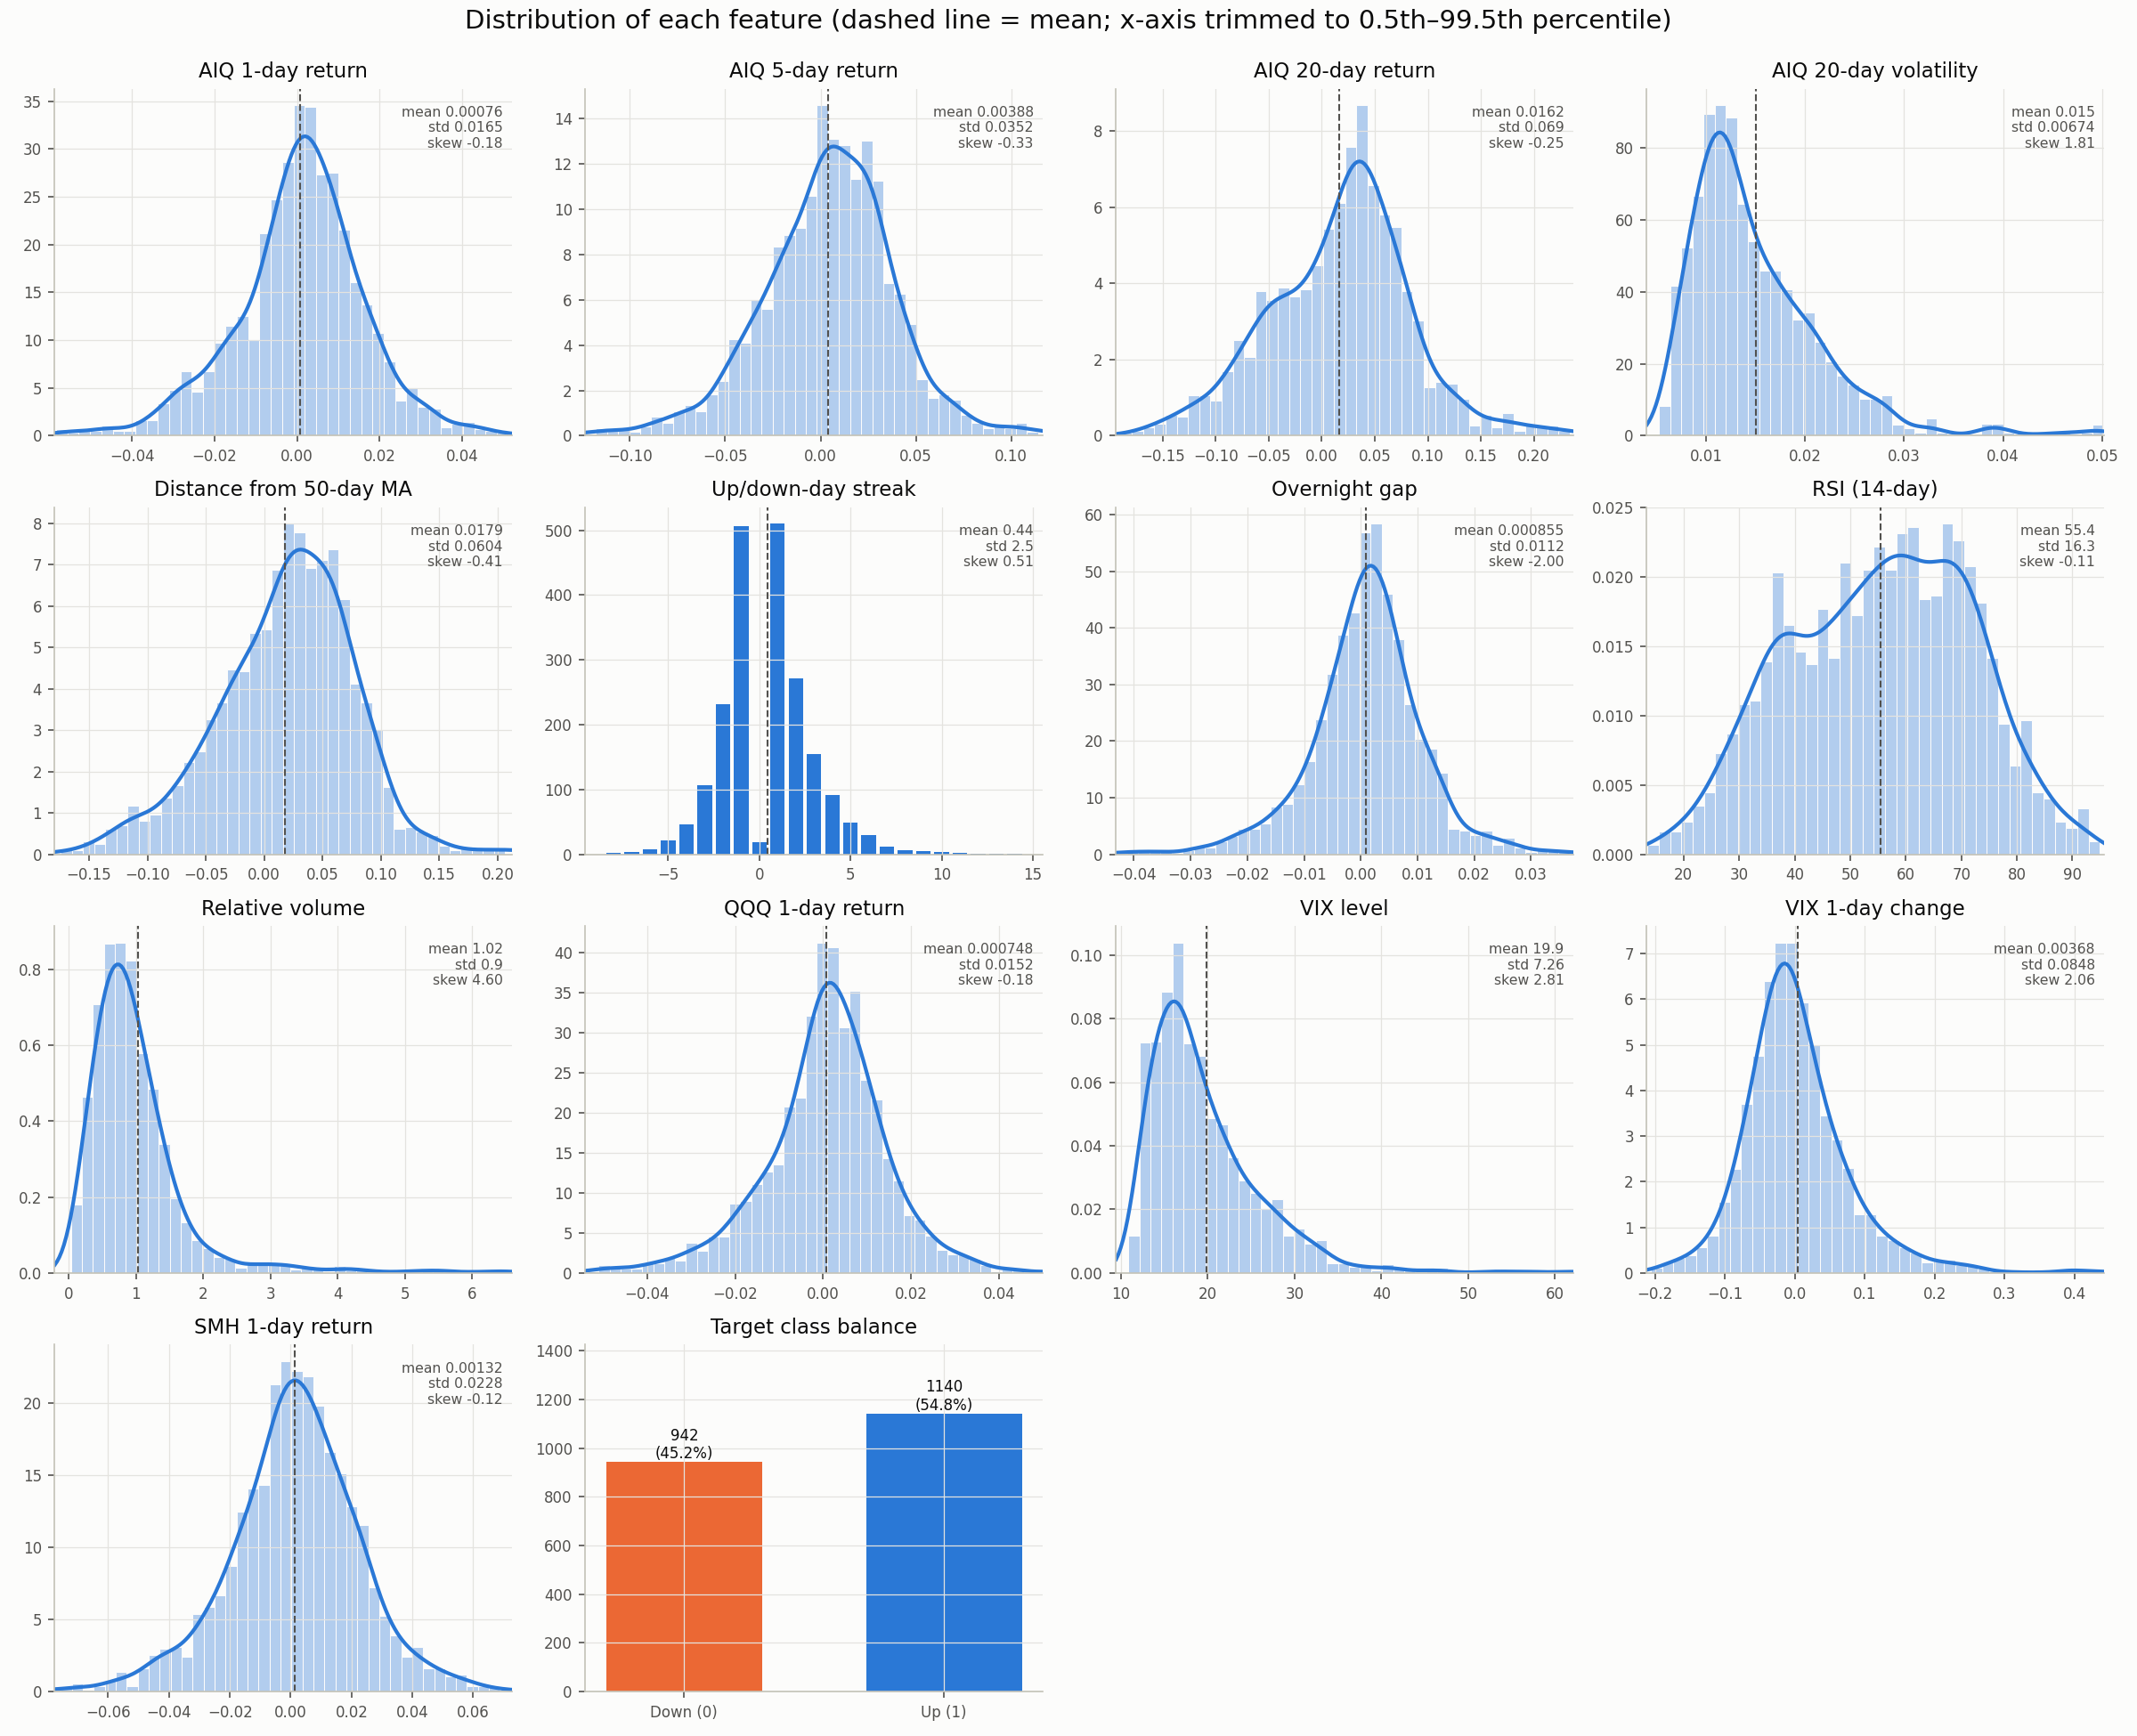

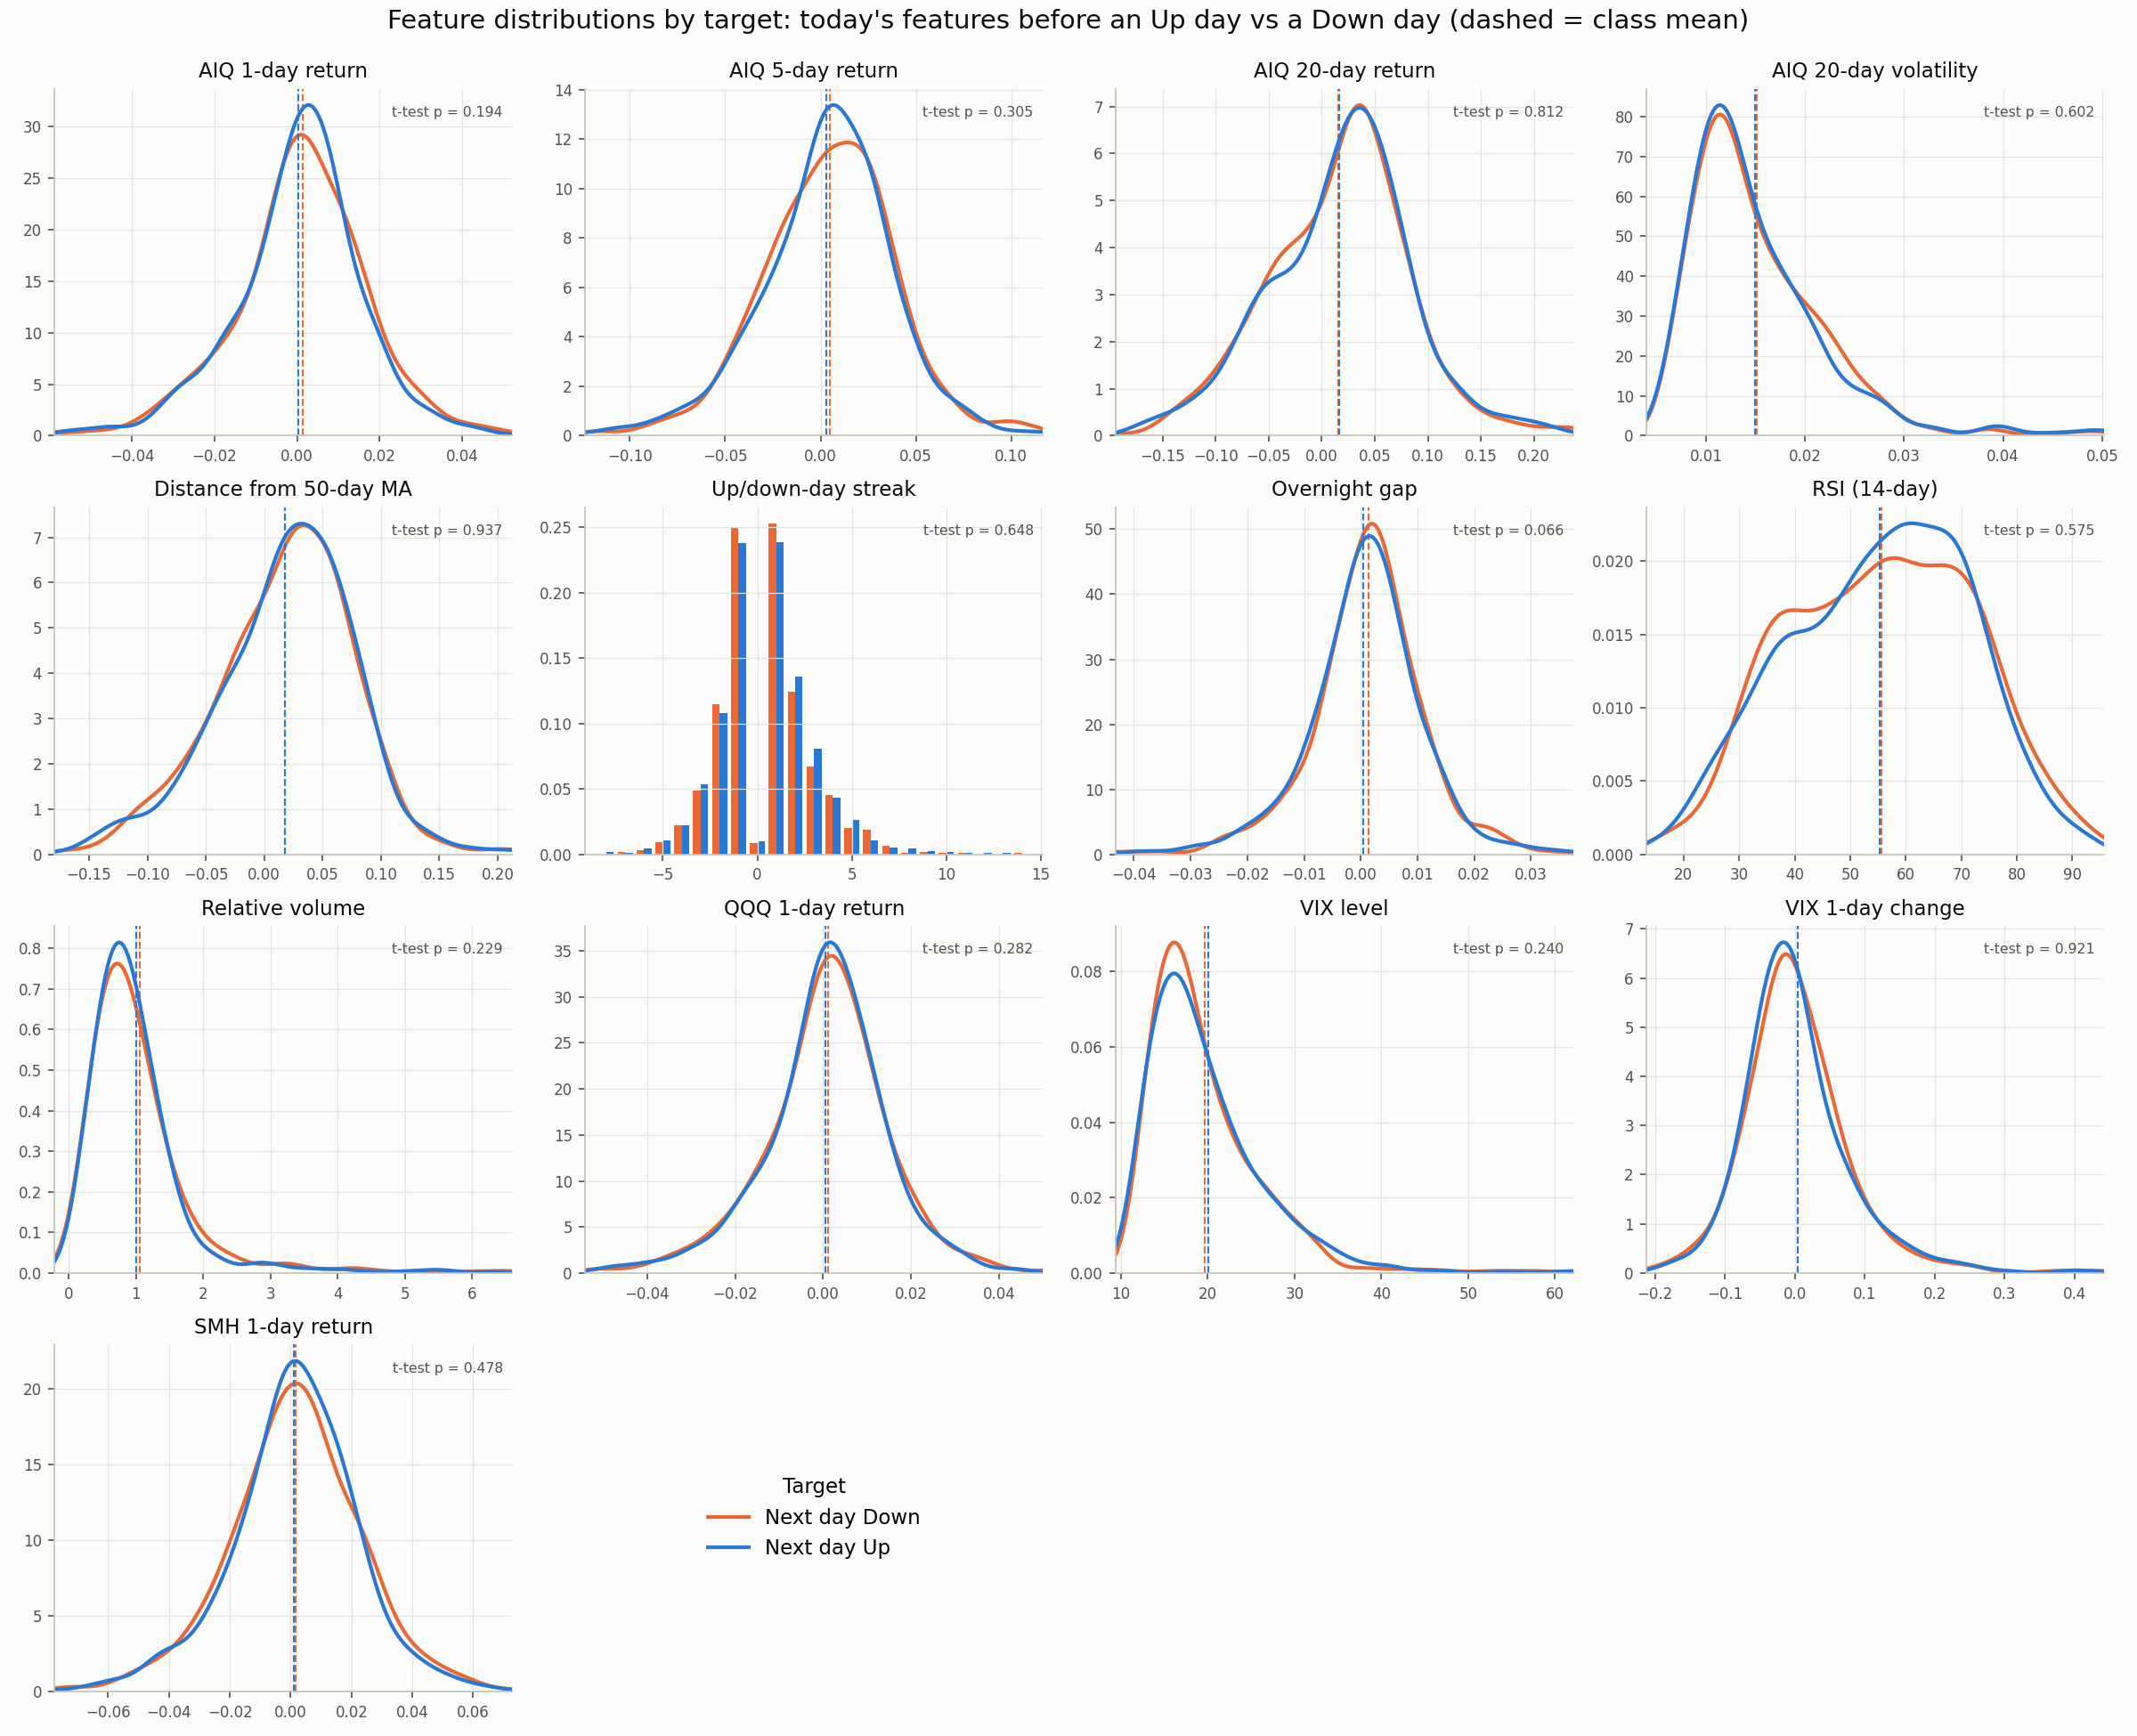

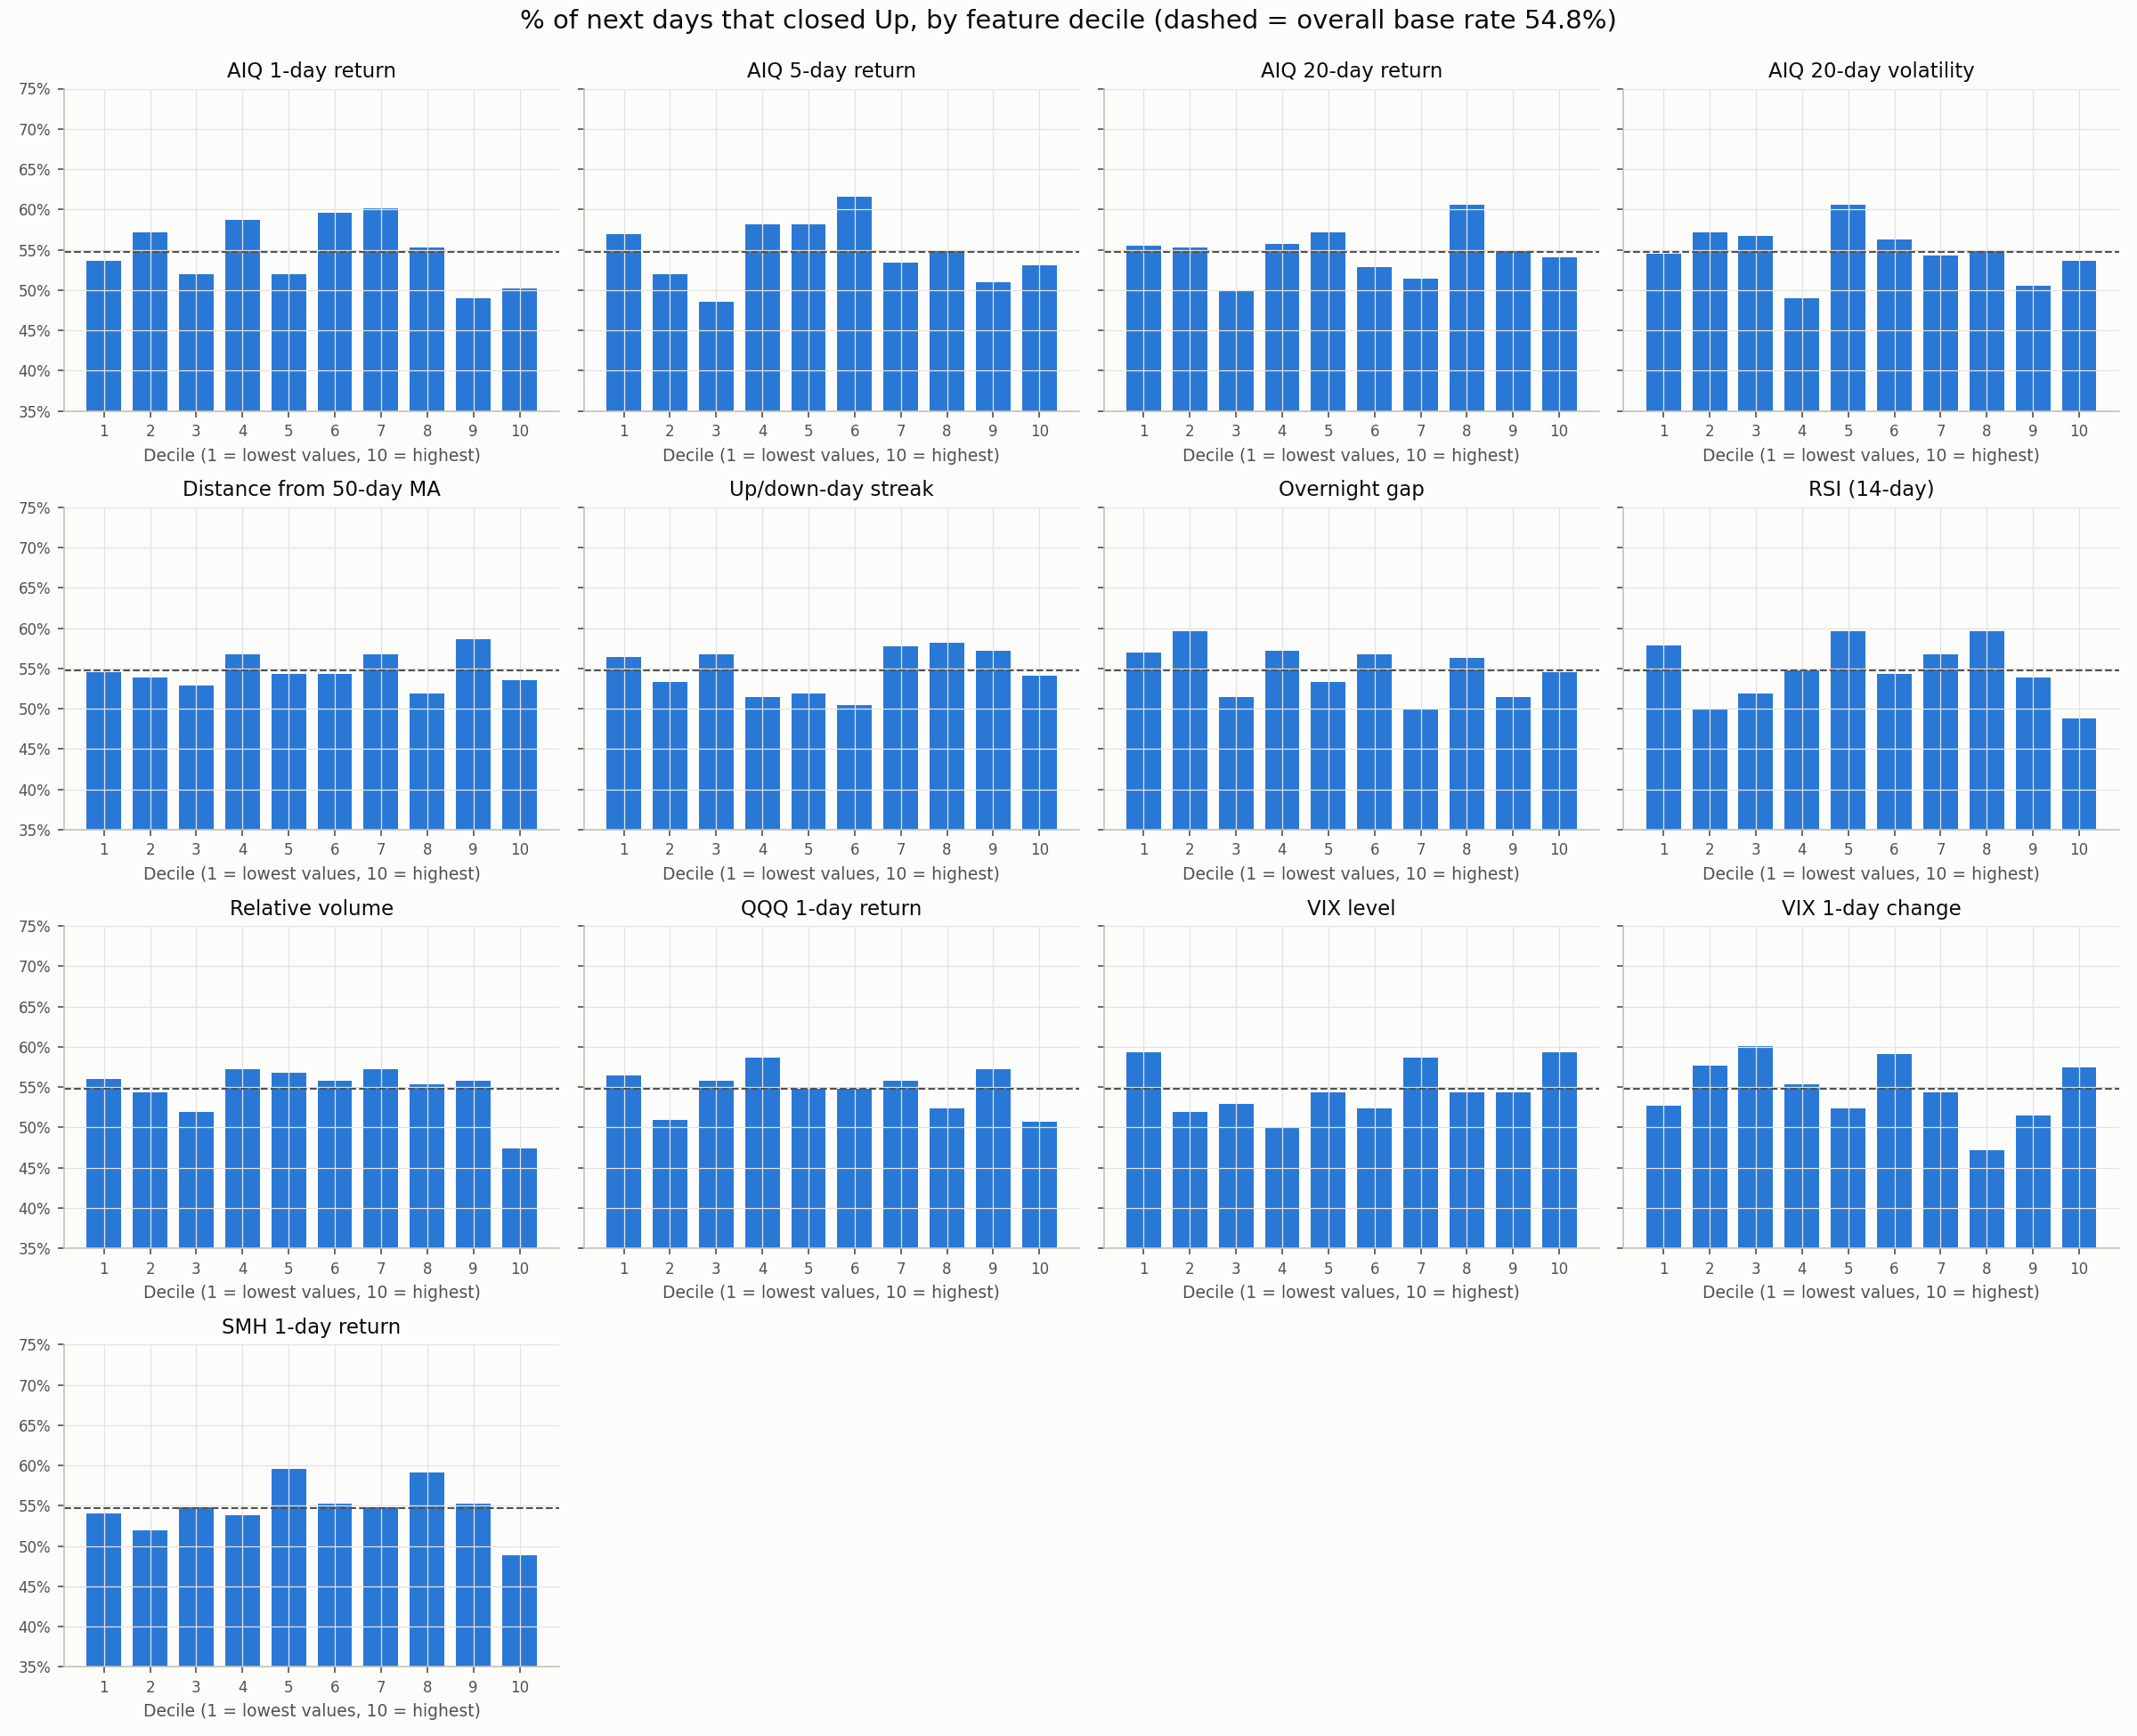

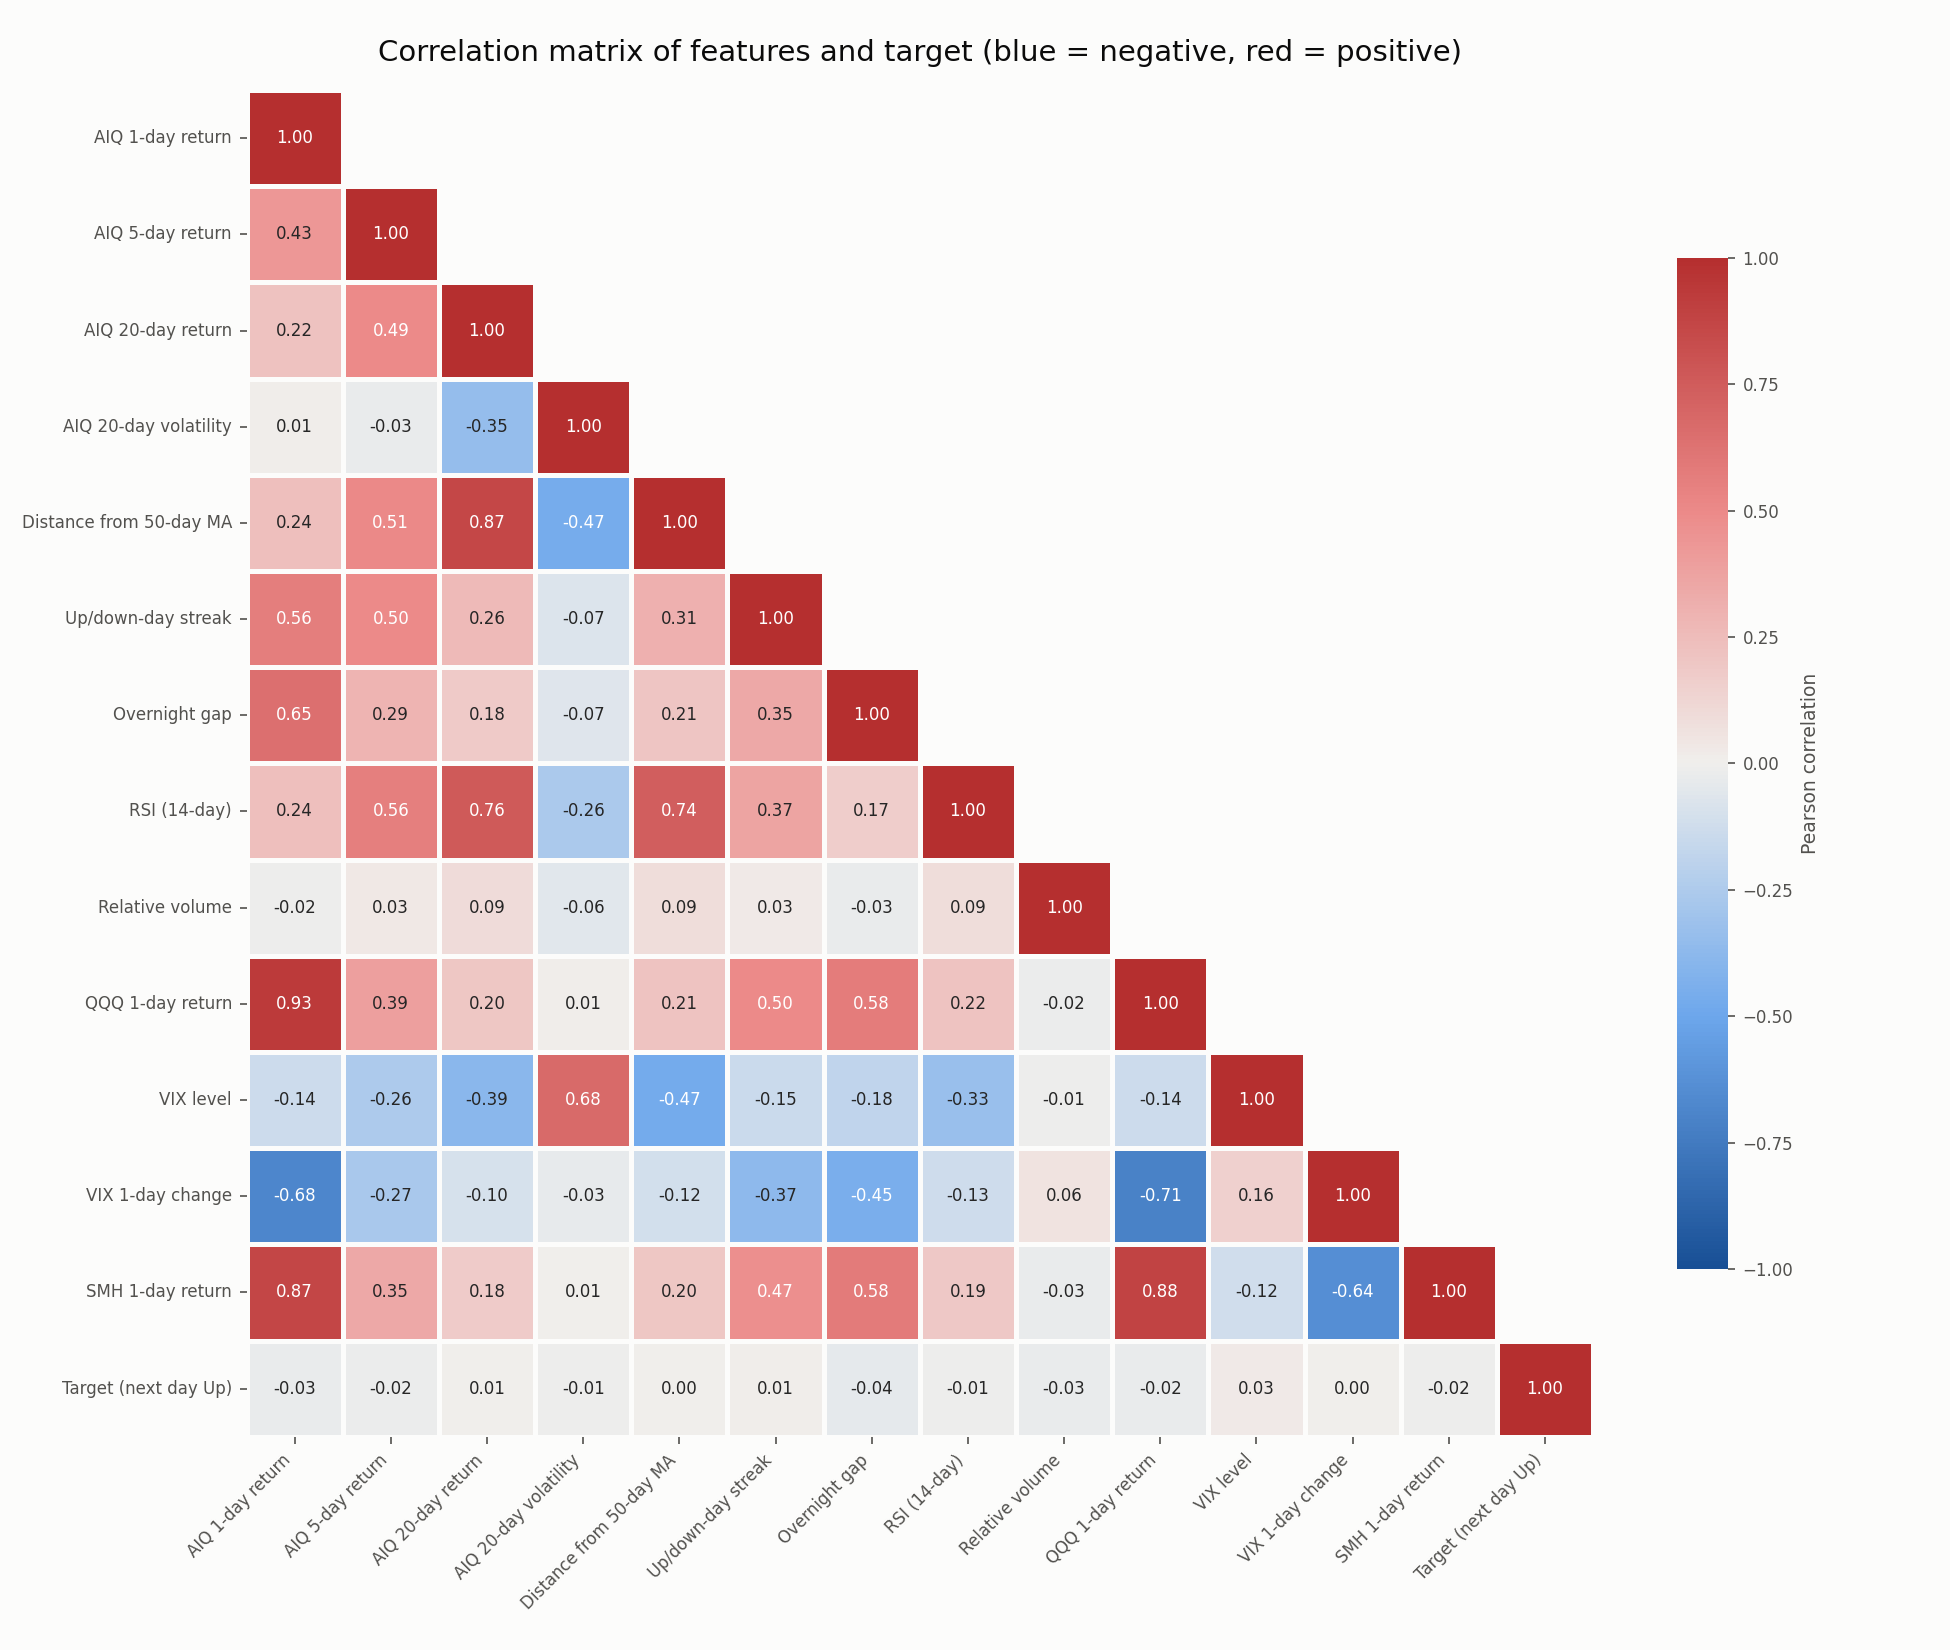

In [6]:
from IPython.display import Image, display

for name in ["feature_distributions", "features_by_target", "up_rate_by_decile", "correlation_matrix"]:
    display(Image(filename=os.path.join(FIG_DIR, f"{name}.png")))

## data_preprocessing.py

In [7]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None) # avoids cutting columns off early when printing
pd.set_option('display.width', 200) # sets character limit to 200 on wideness when printing

'''
Site I used for reference: https://www.geeksforgeeks.org/data-analysis/data-preprocessing-machine-learning-python/
'''

def split_data(df, validate_year = 2024, test_year=2025):
    df = df.sort_index()  # Ensure the DataFrame is sorted by date
    
    train_df = df[ df.index.year < validate_year ] 
    validate_df = df[ df.index.year == validate_year]
    test_df = df[ df.index.year >= test_year ] 

    # Ranges (report it in the write-up)
    print(f"Train: {train_df.index.min().date()} to {train_df.index.max().date()} ({len(train_df)} rows)")
    print(f"Validate: {validate_df.index.min().date()} to {validate_df.index.max().date()} ({len(validate_df)} rows)")
    print(f"Test:  {test_df.index.min().date()} to {test_df.index.max().date()} ({len(test_df)} rows)")

    return train_df, validate_df, test_df


def preprocessing(dfo): # df is the dataset created in featureCreation.py
    '''
    The idea is:
    1. Check for missing values and data types of each column
    2. Log transformations (log(x): Rel_Volume, VIX_Level, 20D_Volatility; log1p(x): VIX_1D_Change (can be negative)) --> found from feature distributions
    3. Split data into train (2024 > year), validation (2024), testing (2025 <= year)
    4. clip with train bounds (cap on extreme values so it doesn't blow up data) --> found from feature distributions
    5. Standardize data into mean=0, SD=1 to ensure features stand equally, and one doesn't blow up the data
    '''
    print(dfo.info()) # count of non-null entries and data type of each column.
    print("--------------------------------")
    print(dfo.isnull().sum()) # Returns the number of missing values per column.
    print("--------------------------------")
    # df.describe(): Computes count, mean, std deviation, min/max and quartiles for numerical columns.
    print(dfo.describe())

    # features in README as well
    features = [
        '1D_Return', '5D_Return', '20D_Return', 
        '20D_Volatility', 'Dist_50D_MA', 
        'Up_Day_Streak', 'Overnight_Gap', 
        'RSI', 'Rel_Volume', 'QQQ_1D_Return', 
        'VIX_Level', 'VIX_1D_Change', 
        'SMH_1D_Return'
        ]

    '''
    Log transformations on Rel_Volume, VIX_Level, 20D_Volatility, VIX_1D_Change
    '''
    df = dfo.copy() # copy so we don't modify original data
    for c in ['Rel_Volume', 'VIX_Level', '20D_Volatility']:
        df[c] = np.log(df[c])
    df['VIX_1D_Change'] = np.log1p(df['VIX_1D_Change'])

    ### Splitting data into train, validate, test ###
    train_df, validate_df, test_df = split_data(df, 2024, 2025)
    # seperating features from target since we dont want to clip or standardize the target
    X_train,    y_train    = train_df[features],    train_df['Target']
    X_validate, y_validate = validate_df[features], validate_df['Target']
    X_test,     y_test     = test_df[features],     test_df['Target']

    #################################################

    '''
    clipping training bounds
    --> Clip on training data only, apply rules to train, validation, and test to avoid data leakage
    '''
    lo = X_train.quantile(0.01) # 1st percentile
    hi = X_train.quantile(0.99) # 99th percentile
    
    lo['Up_Day_Streak'], hi['Up_Day_Streak'] = -5, 5 # +-5 streak rule to not blow up data
    
    X_train = X_train.clip(lo, hi, axis=1) # axis=1 --> columns, since we apply clippings to features, not rows
    X_validate = X_validate.clip(lo, hi, axis=1)
    X_test = X_test.clip(lo, hi, axis=1)

    '''
    Standardization of data --> mean = 0, standard deviation = 1 for all features
     - allows each feature to be in similar ranges, 
    '''
    scaler = StandardScaler() # empty scalar, using fit_transform to populate it
    # StandardScaler returns NumPy arrays, which drop the column names and dates so we wrap it in a DataFrame
    X_train    = pd.DataFrame(scaler.fit_transform(X_train), columns=features, index=X_train.index) # fit_transform --> compute each feature's mean and standard deviation from given data and store it
    X_validate = pd.DataFrame(scaler.transform(X_validate),  columns=features, index=X_validate.index) # transform --> apply stored mean and std to convert data with z = (x − mean) / std 
    X_test     = pd.DataFrame(scaler.transform(X_test),      columns=features, index=X_test.index)
    
    # save the post-processed data for inspection only (the models use the returned variables)
    processed = pd.concat([
        X_train.assign(Target=y_train, Split="train"),
        X_validate.assign(Target=y_validate, Split="validate"),
        X_test.assign(Target=y_test, Split="test"),
    ])
    processed.to_csv("Datasets/Preprocessed_Dataset.csv")

    print("Preprocessed dataset (first rows):\n", processed.head())
    print("X_train summary (should be mean 0, std 1):\n", X_train.describe())

    return X_train, X_validate, X_test, y_train, y_validate, y_test

## main.py

In [8]:
from yahooFinance import download_data
from featureCreation import feature_creation
from data_preprocessing import preprocessing

def main():

    download_data() # retrieves data from Yahoo Finance and saves as CSV files in /Datasets

    df = feature_creation() # Create features based on CSV files downlaoded in /Datasets and output Model_Dataset.csv
    print("df", df.head())

    '''
    Preprocess data (data_preprocess.py) --> returns split data with following changes:
        1. Check for missing values and data types of each column
        2. Log transformations (log(x): Rel_Volume, VIX_Level, 20D_Volatility; log1p(x): VIX_1D_Change (can be negative)) --> found from feature distributions
        3. Split data into train (2024 > year), validation (2024), testing (2025 <= year)
        4. clip with train bounds (cap on extreme values so it doesn't blow up data) --> found from feature distributions
        5. Standardize data into mean=0, SD=1 to ensure features stand equally, and one doesn't blow up the data
    '''
    X_train, X_validate, X_test, y_train, y_validate, y_test = preprocessing(df)

    # Section D: train models


if __name__ == "__main__":
    main()

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


<class 'pandas.DataFrame'>
DatetimeIndex: 2133 entries, 2018-05-16 to 2026-11-09
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   2133 non-null   float64
 1   High    2133 non-null   float64
 2   Low     2133 non-null   float64
 3   Open    2133 non-null   float64
 4   Volume  2133 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 100.0 KB
<class 'pandas.DataFrame'>
DatetimeIndex: 2217 entries, 2018-01-16 to 2026-11-09
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   2217 non-null   float64
 1   High    2217 non-null   float64
 2   Low     2217 non-null   float64
 3   Open    2217 non-null   float64
 4   Volume  2217 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 103.9 KB
<class 'pandas.DataFrame'>
DatetimeIndex: 2219 entries, 2018-01-16 to 2026-11-09
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
--